> **한눈에 보기**
> - 임베딩·벡터 DB 개념 → pgvector에 저장하고 SQL로 유사도 검색 → RAG
> - 정리 문서: [RAG.md](RAG.md)

**벡터DB**
- 벡터 DB(Vector Database, 벡터 데이터베이스)는 전통적인 텍스트나 숫자 대신, **데이터의 의미와 문맥을 숫자의 배열(벡터, Vector, 임베딩값)** 로 변환하여 저장하고 **유사도**로 검색하는 데 특화된 고성능 데이터베이스입니다.

- 기존의 관계형 DB(MySQL 등) DB는 키워드가 정확히 일치해야 데이터를 찾아냅니다. 반면 벡터 DB는 **말뜻(의미)이 통하는 것**을 찾아냅니다.

- LLM(대형 언어 모델)이 대중화되면서 AI가 데이터를 기억하고 검색하는 '장기 기억 장치(RAG)'로 필수적인 역할을 하고 있습니다.

> 한화내일아카데미 10월 15일 수업 실습 노트북입니다. (강사님 자료 `basicedu/exam3.ipynb`)
> - 로컬 도커로 띄운 pgvector(PostgreSQL + 벡터 확장)에 OpenAI 임베딩을 저장하고, SQL로 유사도 검색과 RAG를 실습했습니다.
> - 강의 슬라이드 이미지(강사님이 AI로 만든 그림 등)는 강사님 허락을 받아 그대로 넣었습니다.
> - 예제 문장에 있던 강사님 개인 정보(실명, 사는 곳)는 `OOO`, `OO`로 가렸습니다. 유사도 값은 원래 문장으로 계산된 결과입니다.
> - DB 접속 정보(`edu` / `1234`)는 실습용 로컬 도커 컨테이너의 값입니다.
> - **📝 정리** 셀은 실행 결과를 보고 직접 정리한 내용입니다.

- 임베딩 (Embedding): 비정형 데이터(텍스트, 이미지, 오디오 등)를 인공지능 모델을 거쳐 수백~수천 개의 숫자로 이루어진 좌표 값(벡터)으로 변환합니다. 이 과정에서 의미가 비슷한 데이터들은 3차원 공간상의 가까운 위치(좌표)에 모이게 됩니다.

- 벡터 DB 저장: 이렇게 변환된 고차원 좌표 데이터를 벡터 DB에 저장합니다.

- 유사도 검색 (Similarity Search): 사용자가 질문을 던지면 그 질문도 좌표(벡터)로 바꾼 뒤, 공간에서 가장 거리가 가까운 데이터들을 순식간에 찾아냅니다. (이때 코사인 유사도, 유클리드 거리 등의 수학적 계산법이 쓰입니다.)

**pgvector** 는 기존 데이터베이스(**postgresql**)에 벡터 검색 기능을 추가한 **확장형 벡터DB** 입니다.

[ 기동시키는 방법 ]
- 도커데스크탑을 실행
- 볼륨 생성(최초 한 번) : **docker volume create vpg** 
- pgvector 를 도커 컨테이너로 생성하고 기동 : **docker run -p 5432:5432 -d  -e POSTGRES_USER=edu -e POSTGRES_PASSWORD=1234  -e POSTGRES_DB=edudb  -v vpg:/var/lib/postgresql/data --name edupgvector ankane/pgvector** 
- 볼륨과 컨테이너가 이미 생성된 경우라면 : **docker start edupgvector**
- 도커 컨테이너 기동된 상황 채크 : **docker ps**

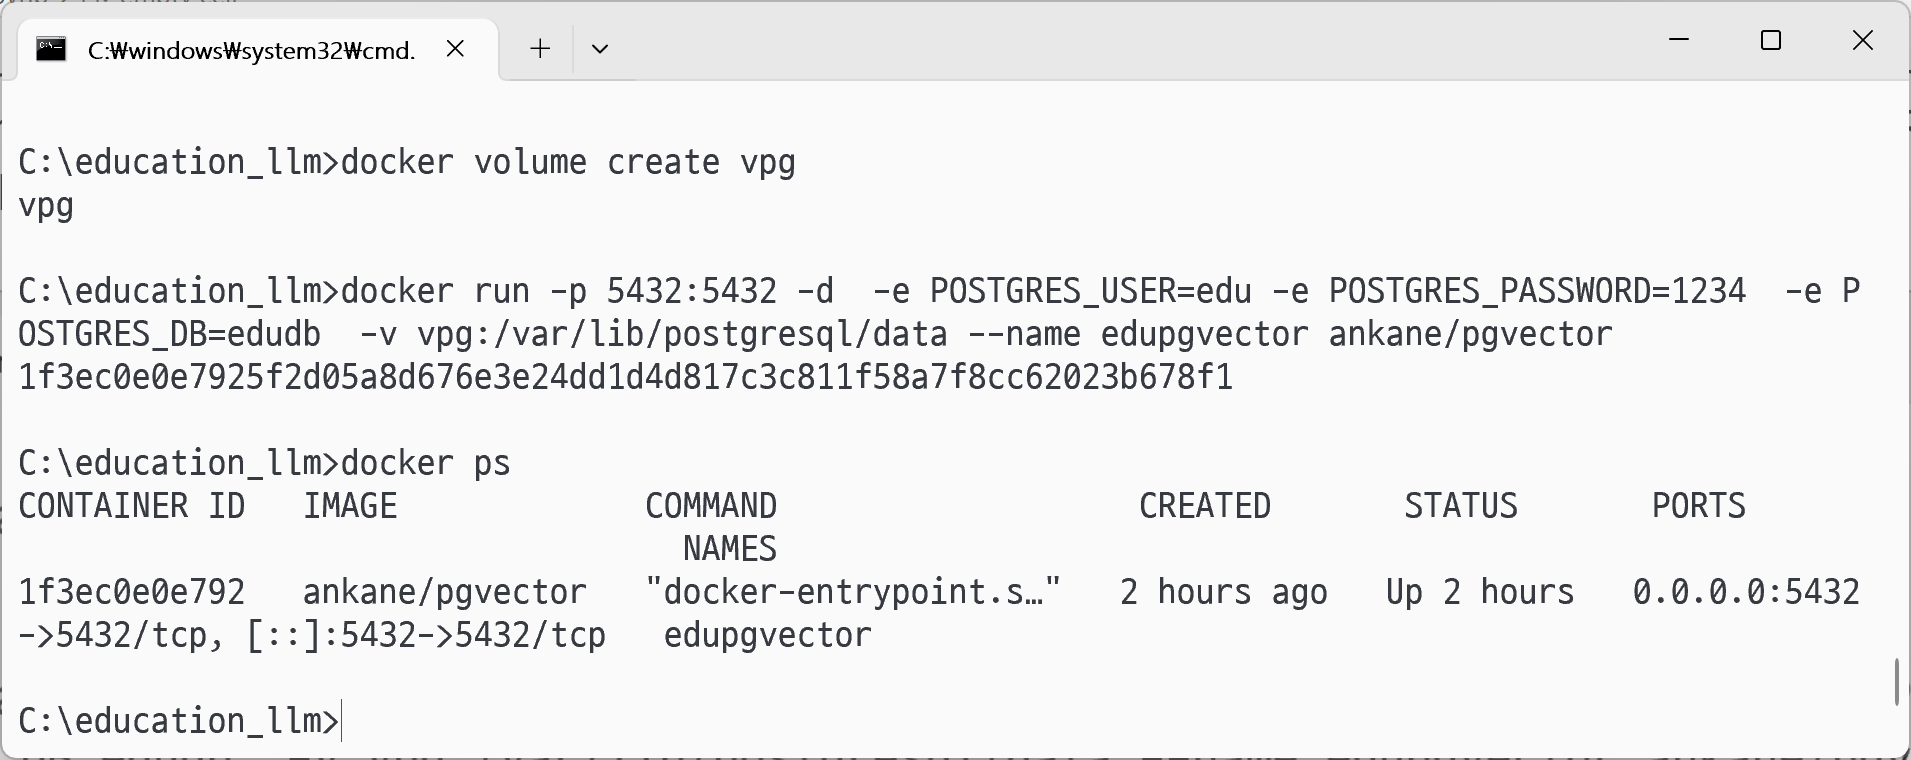

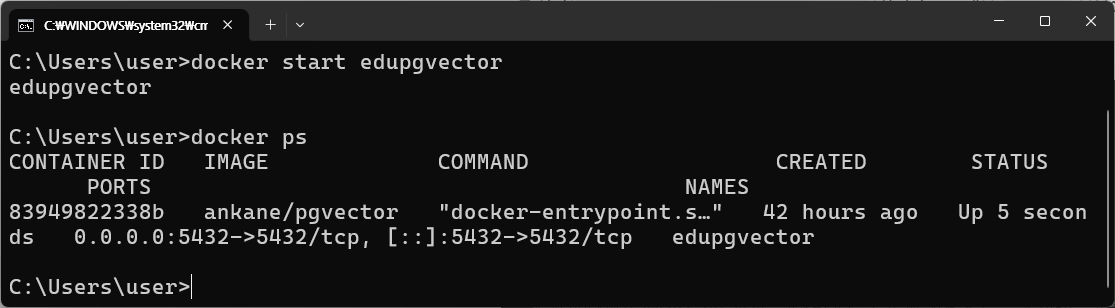

**벡터(vector)타입**
- 벡터는 단순히 방향과 크기를 가진 화살표라는 기하학적 의미를 넘어,  **데이터의 의미적 특징(Semantic Features)** 을 숫자 배열로 표현한 것입니다.
- 임베딩 벡터(Embedding Vector)라고도 부릅니다.
- 차원(Dimension, $N$): 벡터를 구성하는 숫자의 개수입니다. <br>
  OpenAI의 text-embedding-3-small 모델은 기본적으로 1,536 차원의 벡터 타입을 가집니다. <br>
  차원이 높을수록 데이터의 복잡한 의미를 더 정교하게 담을 수 있습니다.

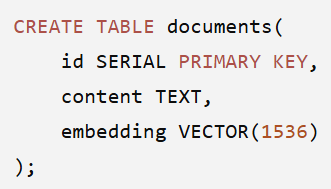

- 의미가 유사한 데이터는 고차원 공간에서 서로 가까이 위치한다 기하학적 가정 덕분에 벡터 DB는 두 벡터 데이터 간의 거리나 각도를 계산하여 유사도를 측정합니다.

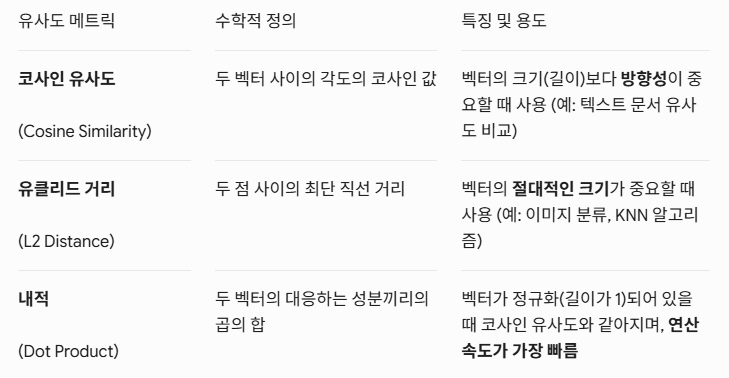

- pgvector 에서 지원하는 고차원 벡터간의 유사도 계산 연산자
- <=> : 코사인 거리 (Cosine Distance) -  벡터의 크기(길이)보다 두 벡터가 가리키는 방향이 얼마나 다른지를 봅니다.
- <-> : 유클리드 거리 (L2 Distance) - 기하학적인 직선 거리이며 두 벡터의 크기와 방향을 모두 고려합니다.
- <#> : 음수 내적 (Negative Dot Product) - 내적(Dot Product)은 값이 클수록 유사도가 높습니다. 내적 값에 마이너스(-)를 붙인 음수 내적 연산자를 사용합니다.


- **코사인 거리(Cosine Distance)**<br>
  embedding <=> query_vector
- **코사인 유사도(Cosine Similarity)**<br>
  1 - 코사인 거리

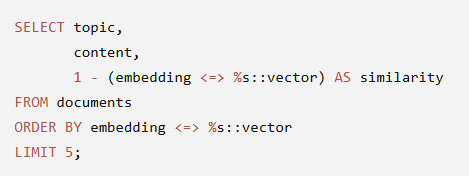  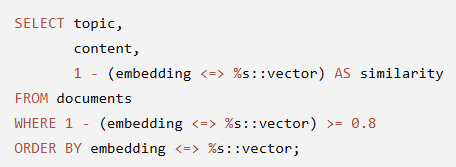   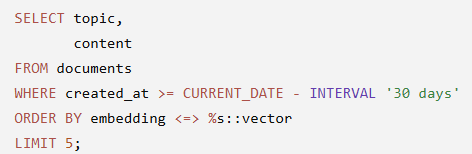

**실무에서 특히 기억하면 좋은 핵심 포인트**
- 거리(distance)와 유사도(similarity)를 구분하세요. <br>
  <=>는 유사도가 아니라 거리를 반환하므로 화면에 보여줄 때는 **1 - distance**처럼 변환해 사용합니다.
- 정렬은 항상 거리 기준으로 합니다. <br>
  **ORDER BY embedding <=> %s::vector LIMIT k** 형태가 pgvector 인덱스를 가장 잘 활용하는 기본 패턴입니다.
- 타입을 맞추는 것이 중요합니다. <br>
  Python에서 전달한 값이 numeric[]로 해석되면 vector와 연산할 수 없으므로 **%s::vector**와 같은 명시적 캐스팅합니다.
- 연산자와 인덱스는 함께 생각하세요. <br>
  코사인 거리(<=>)를 사용할 계획이라면 vector_cosine_ops 인덱스를, L2 거리(<->)라면 vector_l2_ops를 사용하는 것이 성능에 중요합니다.

**📝 정리** — pgvector의 `<=>`는 **유사도가 아니라 거리**를 돌려준다(코사인 거리 = 1 − 코사인 유사도). 그래서 정렬은 거리 오름차순(`ORDER BY embedding <=> 질문벡터`)으로 하고, 화면에 보여 줄 때만 `1 - 거리`로 바꾼다. 파이썬 리스트를 넘길 때는 `%s::vector`로 형을 맞춰야 한다.

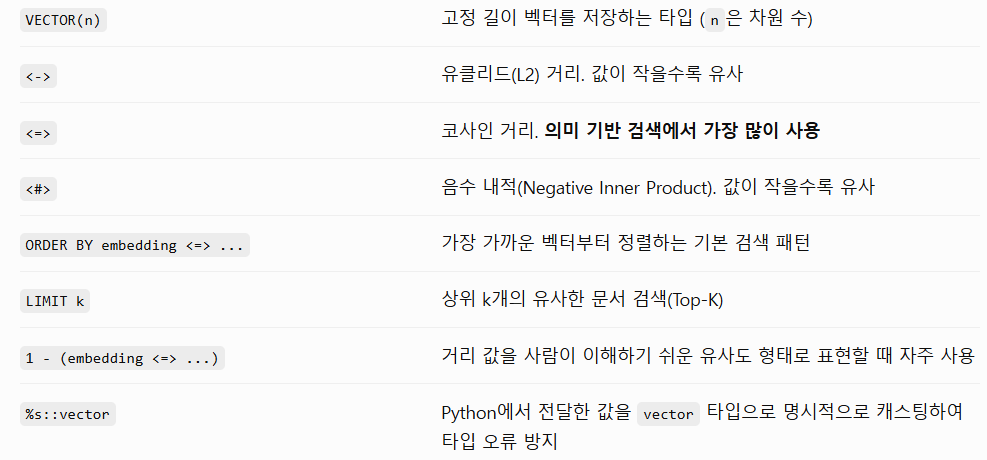

**임베딩한 벡터값 저장**

In [1]:
import os
from openai import OpenAI
import psycopg

# 1. OpenAI 클라이언트 및 데이터베이스 연결 설정
client = OpenAI()

DB_PARAMS = {
    "host": "localhost",
    "port": 5432,
    "user": "edu",
    "password": "1234",
    "dbname": "edudb"
}


# 2. text-embedding-3-small 모델로 임베딩 벡터 생성
def get_embedding(text):
    response = client.embeddings.create(
        model="text-embedding-3-small",
        input=text
    )
    return response.data[0].embedding


# 3. 데이터베이스 초기화 및 데이터 저장 함수
def init_db_and_insert_documents():

    documents = [
        "AX(AI Transformation)는 기업 경영 전반에 인공지능을 도입하여 비즈니스 모델을 혁신하는 과정입니다.",
        "FastAPI는 파이썬 3.8+ 기반의 아주 빠르고 직관적인 최신 웹 프레임워크로, 비동기 처리에 강점이 있습니다.",
        "Docker Compose를 사용하면 여러 개의 컨테이너로 이루어진 개발 환경을 단 하나의 명령어로 깔끔하게 셋업할 수 있습니다.",
        "OpenAI의 text-embedding-3-small 모델은 텍스트를 1536차원의 고밀도 숫자 벡터로 변환해 줍니다.",
        "RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.",
        "OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다."
    ]

    print("🔌 PostgreSQL 연결 중...")

    # psycopg3 연결
    with psycopg.connect(**DB_PARAMS) as conn:
        with conn.cursor() as cur:

            # pgvector 확장 및 테이블 생성
            print("🛠️ mydoc1 테이블 생성 중...")

            cur.execute("CREATE EXTENSION IF NOT EXISTS vector;")
            cur.execute("DROP TABLE IF EXISTS mydoc1;")

            cur.execute("""
                CREATE TABLE mydoc1 (
                    id SERIAL PRIMARY KEY,
                    content TEXT,
                    embedding vector(1536)
                );
            """)

            # 임베딩 생성
            print("🧠 문서 임베딩 생성 중...")

            data_to_insert = []

            for doc in documents:
                vector = get_embedding(doc)

                # PostgreSQL vector 타입에 맞게 문자열로 변환
                data_to_insert.append((doc, str(vector)))

            # psycopg3의 executemany() 사용
            print("💾 PostgreSQL에 벡터 저장 중...")

            cur.executemany(
                """
                INSERT INTO mydoc1 (content, embedding)
                VALUES (%s, %s::vector)
                """,
                data_to_insert
            )

    # with 블록 정상 종료 시 자동 COMMIT 및 연결 종료
    print(f"✅ {len(documents)}개의 문서가 저장되었습니다!")


if __name__ == "__main__":
    init_db_and_insert_documents()


🔌 PostgreSQL 연결 중...
🛠️ mydoc1 테이블 생성 중...
🧠 문서 임베딩 생성 중...
💾 PostgreSQL에 벡터 저장 중...
✅ 6개의 문서가 저장되었습니다!


In [2]:
init_db_and_insert_documents()

🔌 PostgreSQL 연결 중...
🛠️ mydoc1 테이블 생성 중...
🧠 문서 임베딩 생성 중...
💾 PostgreSQL에 벡터 저장 중...
✅ 6개의 문서가 저장되었습니다!


**📝 정리** — 같은 함수를 한 번 더 실행했지만 `DROP TABLE IF EXISTS mydoc1` 후 다시 만들기 때문에 문서가 중복되지 않고 그대로 6개다. 문서마다 `get_embedding()`을 따로 불러서 임베딩 API를 6번 호출한다(여러 문장을 `input`에 리스트로 넘기면 한 번에 받을 수 있다).

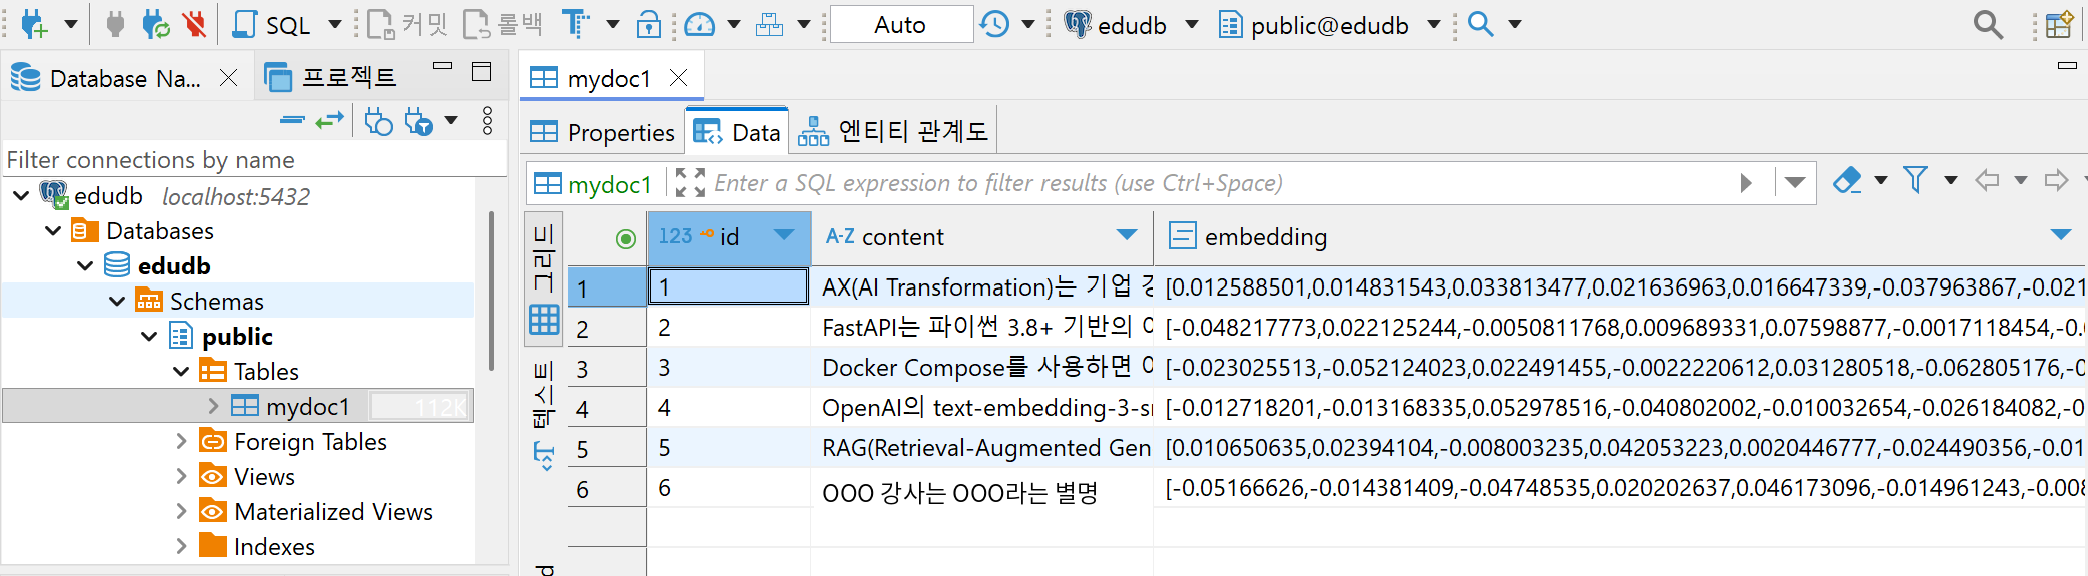

---

In [3]:

import os
import psycopg
from openai import OpenAI
from pgvector.psycopg import register_vector

conn = None

DB_CONFIG = {
    "host": "localhost",
    "port": 5432,
    "dbname": "edudb",
    "user": "edu",
    "password": "1234"
}


def get_conn():
    global conn
    conn = psycopg.connect(**DB_CONFIG)
    register_vector(conn)
    return conn


EMBEDDING_MODEL = "text-embedding-3-small"

client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])


def get_embedding(text):
    res = client.embeddings.create(
        model=EMBEDDING_MODEL,
        input=text
    )
    return res.data[0].embedding


def run_sql(title, sql, params):
    conn = get_conn()

    print("=" * 70)
    print(title)
    print("=" * 70)

    try:
        with conn.cursor() as cur:
            cur.execute(sql, params)

            rows = cur.fetchall()

            for r in rows:
                print(r)

    finally:
        conn.close()


In [4]:
sql1 = """
SELECT content
FROM mydoc1
ORDER BY embedding <=> %s::vector
LIMIT 3
"""

In [5]:
run_sql("TOP3", sql1, (get_embedding("별명"),))

TOP3
('OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.',)
('RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.',)
('Docker Compose를 사용하면 여러 개의 컨테이너로 이루어진 개발 환경을 단 하나의 명령어로 깔끔하게 셋업할 수 있습니다.',)


In [6]:
run_sql("TOP3", sql1, (get_embedding("오뎅"),))

TOP3
('OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.',)
('RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.',)
('Docker Compose를 사용하면 여러 개의 컨테이너로 이루어진 개발 환경을 단 하나의 명령어로 깔끔하게 셋업할 수 있습니다.',)


**📝 정리** — "별명"과 "오뎅"으로 검색한 TOP3가 순서까지 똑같았다. `ORDER BY ... LIMIT 3`은 관련이 있든 없든 **항상 가장 가까운 3개**를 돌려주기 때문이다. "오뎅"이 강사님 소개 문장(떡볶이를 좋아함)을 1위로 찾은 건 분식이라는 의미가 이어져서지만, 관련 없는 문서도 2, 3위로 같이 나온다.

In [7]:
sql2 = """
SELECT content,
    1-(embedding <=> %s::vector) AS similarity
FROM mydoc1
ORDER BY embedding <=> %s::vector
LIMIT 2
"""

In [8]:
emd = get_embedding("오뎅")
run_sql("Similarity", sql2, (emd, emd))

Similarity
('OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.', 0.1636387277791047)
('RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.', 0.1431443784988765)


**📝 정리** — 유사도를 같이 출력해 보니 "오뎅"의 1위가 0.164, 2위가 0.143으로 차이가 거의 없다. 순위만 보면 1위지만 수치로는 관련이 약하다. 실제 서비스에서는 `WHERE 유사도 >= 임계값`처럼 기준을 두어야 엉뚱한 문서를 근거로 쓰지 않는다.

In [9]:
sql = """
SELECT
    content,
    embedding <=> %s::vector AS distance,
    1-(embedding <=> %s::vector) AS similarity
FROM mydoc1
ORDER BY distance;
"""

In [10]:
emd = get_embedding("집")
run_sql("Distance vs Similarity", sql,  (emd, emd))

Distance vs Similarity
('OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.', 0.7964467818028624, 0.20355321819713756)
('Docker Compose를 사용하면 여러 개의 컨테이너로 이루어진 개발 환경을 단 하나의 명령어로 깔끔하게 셋업할 수 있습니다.', 0.8467663329976381, 0.15323366700236185)
('RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.', 0.8707443096025866, 0.12925569039741336)
('AX(AI Transformation)는 기업 경영 전반에 인공지능을 도입하여 비즈니스 모델을 혁신하는 과정입니다.', 0.907767936118488, 0.09223206388151195)
('FastAPI는 파이썬 3.8+ 기반의 아주 빠르고 직관적인 최신 웹 프레임워크로, 비동기 처리에 강점이 있습니다.', 0.9289198744944299, 0.07108012550557008)
('OpenAI의 text-embedding-3-small 모델은 텍스트를 1536차원의 고밀도 숫자 벡터로 변환해 줍니다.', 0.9492738977774774, 0.05072610222252261)


**📝 정리** — `집`으로 검색하니 "…에서 살고 있습니다"가 들어 있는 강사님 소개 문장이 0.204로 1위였다. 단어가 겹치지 않아도 '사는 곳'이라는 의미로 찾은 것이다. 모든 행에서 거리 + 유사도 = 1이다.

In [11]:
emd = get_embedding("OOO강사는 어떤 음식을 좋아할까?")
run_sql("Distance vs Similarity", sql,  (emd, emd))

Distance vs Similarity
('OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.', 0.4539390980261513, 0.5460609019738487)
('RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.', 0.921630389053591, 0.07836961094640904)
('Docker Compose를 사용하면 여러 개의 컨테이너로 이루어진 개발 환경을 단 하나의 명령어로 깔끔하게 셋업할 수 있습니다.', 0.9685761997181622, 0.03142380028183778)
('AX(AI Transformation)는 기업 경영 전반에 인공지능을 도입하여 비즈니스 모델을 혁신하는 과정입니다.', 0.9705079846224353, 0.02949201537756474)
('FastAPI는 파이썬 3.8+ 기반의 아주 빠르고 직관적인 최신 웹 프레임워크로, 비동기 처리에 강점이 있습니다.', 0.979727949276428, 0.020272050723571966)
('OpenAI의 text-embedding-3-small 모델은 텍스트를 1536차원의 고밀도 숫자 벡터로 변환해 줍니다.', 0.9947214889009576, 0.005278511099042427)


**📝 정리** — 질문 문장으로 검색하면 정답 문장의 유사도가 **0.546**, 나머지는 0.08 이하로 차이가 뚜렷했다. text-embedding-3-small로 계산한 유사도는 관련 있는 문장도 0.5 안팎이라, 강의 자료의 해석표(0.9 이상 '매우 유사')나 exam20의 기준(0.6 미만은 '유사도가 낮음')을 그대로 쓰면 이 정답도 '낮음'으로 분류된다. 임계값은 실제 데이터로 값을 확인하고 정해야 한다.

---

**RAG 구현시 프롬프트**

<div>[참고 지식]: <br>
            {context}</div><br>
<div>[질문]: <br>
            {user_question}</div><br>
            
<div>지식을 참고해서 질문에 친절하게 한 문장으로 대답해줘. </div>

In [12]:

# 4. 핵심 RAG 수행 함수 (질문 ➔ 검색 ➔ GPT 답변)
def ask_rag_question(user_question):
    print(f"❓ 사용자 질문: '{user_question}'")

    # 1단계: 질문 임베딩
    question_embedding = get_embedding(user_question)

    # 2단계: pgvector 유사도 검색
    with get_conn() as conn:
        with conn.cursor() as cur:
            cur.execute("""
                SELECT content
                FROM mydoc1
                ORDER BY embedding <=> %s::vector
                LIMIT 1
            """, (str(question_embedding),))

            result = cur.fetchone()

    if not result:
        print("❌ 관련된 문서를 찾지 못했습니다.")
        return

    context = result[0]
    print(f"🔍 Vector DB에서 찾아낸 가장 관련 높은 지식(Context):\n   -> {context}\n")

    # 3단계: GPT-4o-mini 답변 생성
    print("🤖 GPT-4o-mini가 지식을 바탕으로 답변을 생성 중입니다...")

    response = client.responses.create(
        model="gpt-4o-mini",
        instructions="너는 제공된 [참고 지식]만을 바탕으로 정직하게 답변하는 챗봇이야.",
        input=f"[참고 지식]: {context}\n\n[질문]: {user_question}\n\n지식을 참고해서 질문에 친절하게 한 문장으로 대답해줘.",
        temperature=0.3
    )

    ai_answer = response.output_text
    print(f"✨ 최종 AI 답변:\n   -> {ai_answer}\n")


In [13]:
ask_rag_question("AX가 무엇인지 궁금하다. 쉽게 설명해줘")

❓ 사용자 질문: 'AX가 무엇인지 궁금하다. 쉽게 설명해줘'
🔍 Vector DB에서 찾아낸 가장 관련 높은 지식(Context):
   -> AX(AI Transformation)는 기업 경영 전반에 인공지능을 도입하여 비즈니스 모델을 혁신하는 과정입니다.

🤖 GPT-4o-mini가 지식을 바탕으로 답변을 생성 중입니다...
✨ 최종 AI 답변:
   -> AX(AI Transformation)는 기업이 인공지능을 활용해 비즈니스 모델을 혁신하는 과정을 의미합니다.



In [14]:
ask_rag_question("AI가 거짓말하는 환각 현상을 방지하려면 어떤 기술을 써야 해?")

❓ 사용자 질문: 'AI가 거짓말하는 환각 현상을 방지하려면 어떤 기술을 써야 해?'
🔍 Vector DB에서 찾아낸 가장 관련 높은 지식(Context):
   -> RAG(Retrieval-Augmented Generation)는 LLM이 가지는 환각 현상을 방지하기 위해 외부에 저장된 데이터베이스에서 관련 정보를 먼저 검색한 뒤 답변을 생성하는 기술입니다.

🤖 GPT-4o-mini가 지식을 바탕으로 답변을 생성 중입니다...
✨ 최종 AI 답변:
   -> AI의 거짓말하는 환각 현상을 방지하려면 RAG(Retrieval-Augmented Generation) 기술을 사용하여 외부 데이터베이스에서 관련 정보를 검색한 후 답변을 생성해야 합니다.



In [15]:
ask_rag_question("OOO 강사가 좋아하는 음식을 사가야해")

❓ 사용자 질문: 'OOO 강사가 좋아하는 음식을 사가야해'
🔍 Vector DB에서 찾아낸 가장 관련 높은 지식(Context):
   -> OOO 강사는 유니코라는 별명을 가지고 있고 떡볶이를 좋아합니다. OO에서 살고 있습니다.

🤖 GPT-4o-mini가 지식을 바탕으로 답변을 생성 중입니다...
✨ 최종 AI 답변:
   -> OOO 강사는 떡볶이를 좋아하니, 떡볶이를 사가는 것이 좋을 것 같습니다.



**📝 정리** — 질문 → 임베딩 → 가장 가까운 문서 1개(`LIMIT 1`) → 그 문서를 `[참고 지식]`으로 넣어 답변. 세 질문 모두 맞는 문서를 찾아 한 문장으로 답했다. 다만 `LIMIT 1`이라 여러 문서에 걸친 질문은 일부만 참고하고, 유사도 기준이 없어서 관련 문서가 없는 질문에도 가장 가까운 문서 하나를 근거로 답하게 된다.

---

**항공이용가이드 RAG 챗봇**

In [16]:

import os
import psycopg
from pgvector.psycopg import register_vector
from openai import OpenAI

# docker run으로 띄운 pgvector 컨테이너 접속 정보
DB_CONFIG = dict(
    host="localhost",
    port=5432,
    dbname="edudb",
    user="edu",
    password="1234"
)

EMBEDDING_MODEL = "text-embedding-3-small"
EMBEDDING_DIM = 1536

client = OpenAI()

def get_connection(register: bool = True):
    """
    DB 커넥션을 생성하고 pgvector 타입을 등록해서 반환한다.
    vector 확장 생성 전에는 register=False로 호출한다.
    """
    conn = psycopg.connect(**DB_CONFIG, autocommit=True)

    if register:
        register_vector(conn)

    return conn


def init_table():
    """pgvector 확장과 mydoc3 테이블이 없으면 생성한다."""

    conn = get_connection(register=False)

    try:
        with conn.cursor() as cur:
            cur.execute("CREATE EXTENSION IF NOT EXISTS vector;")

            cur.execute(
                f"""
                CREATE TABLE IF NOT EXISTS mydoc3 (
                    id SERIAL PRIMARY KEY,
                    topic TEXT NOT NULL,
                    content TEXT NOT NULL,
                    embedding VECTOR({EMBEDDING_DIM})
                );
                """
            )
    finally:
        conn.close()


def get_embedding(text: str) -> list[float]:
    """텍스트를 OpenAI 임베딩 벡터로 변환한다."""

    response = client.embeddings.create(
        model=EMBEDDING_MODEL,
        input=text
    )

    return response.data[0].embedding


def search_knowledge_base(query: str, top_k: int = 3) -> list[dict]:
    """질문과 가장 관련 있는 항공 이용 안내 내용을 검색한다."""

    query_vector = get_embedding(query)

    sql = """
        SELECT topic, content,
               1 - (embedding <=> %s::vector) AS similarity
        FROM mydoc3
        ORDER BY embedding <=> %s::vector
        LIMIT %s
    """

    conn = get_connection()

    try:
        with conn.cursor() as cur:
            cur.execute(sql, (query_vector, query_vector, top_k))
            rows = cur.fetchall()

    finally:
        conn.close()

    return [
        {
            "topic": r[0],
            "content": r[1],
            "similarity": round(r[2], 4)
        }
        for r in rows
    ]


In [17]:
"""
'항공이용가이드.pdf'를 주제 단위로 나눠 pgvector에 적재합니다.
"""
# 청크를 너무 크게 잡으면 검색 정확도가 떨어지고, 너무 잘게 나누면 맥락이 끊기므로 원문의 소제목 단위로 나눕니다.
DOCS = [
    ("항공권 예약 방법", "고객은 항공사 공식 홈페이지, 모바일 앱, 고객센터 전화, 여행사 및 온라인 여행 플랫폼을 통해 항공권을 예약할 수 있습니다. 예약 시 승객 이름(여권과 동일), 출발지 및 도착지, 여행 날짜, 좌석 등급(이코노미/프레스티지/일등석), 연락처 및 이메일을 입력해야 합니다."),
    ("항공권 예약 확인", "예약 후에는 홈페이지의 '예약 조회' 메뉴, 모바일 앱, 예약 확인 이메일, 또는 예약번호(PNR) 조회를 통해 예약 내용을 확인할 수 있습니다. 확인 시에는 예약번호와 승객 성명이 필요합니다."),
    ("항공권 변경 및 취소", "항공권은 운임 규정에 따라 변경 또는 취소가 가능합니다. 출발 전에는 변경이 가능하지만 일부 할인 운임은 변경 수수료가 발생합니다. 취소 시에는 환불 수수료가 발생할 수 있고, 출발 후 항공권은 일부 환불이 제한됩니다."),
    ("무료 위탁 수하물", "위탁 수하물 허용량은 좌석 등급과 노선에 따라 다릅니다. 이코노미는 23kg 1개, 프레스티지는 32kg 2개, 일등석은 32kg 3개까지 무료로 허용되며, 초과 시 추가 요금이 발생할 수 있습니다."),
    ("기내 반입 수하물", "기내에는 기내 가방 1개와 개인 소지품 1개(노트북 가방, 핸드백 등)를 반입할 수 있습니다. 일반적인 기준은 무게 약 10kg 이하, 크기는 좌석 위 수납 공간에 들어가는 정도입니다."),
    ("기내 반입 제한 물품 및 액체 규정", "날카로운 물건, 인화성 물질, 일부 액체류는 기내 반입이 제한됩니다. 액체류는 100ml 이하 용기에 담아 투명 지퍼백에 보관해야 하며, 총량은 1L를 넘을 수 없습니다."),
    ("공항 도착 권장 시간", "공항 도착 권장 시간은 노선에 따라 다릅니다. 국내선은 출발 1시간 전, 국제선은 출발 2~3시간 전까지 공항에 도착하는 것을 권장합니다."),
    ("체크인 방법", "체크인은 공항 체크인 카운터, 키오스크 체크인, 모바일 체크인, 웹 체크인 중 한 가지 방법으로 할 수 있습니다. 체크인 시에는 여권(국제선의 경우), 예약번호, 항공권 정보가 필요합니다."),
    ("탑승 절차", "탑승 과정은 체크인, 수하물 위탁, 보안 검색, 출국 심사(국제선의 경우), 탑승 게이트 이동, 항공기 탑승 순서로 진행됩니다."),
    ("기내 식사 서비스", "기내 식사는 비행 시간과 노선에 따라 제공됩니다. 장거리 노선은 식사가 2회, 중거리 노선은 1회 제공되며, 단거리 노선에서는 간식이나 음료가 제공됩니다. 채식, 어린이식, 종교식, 저염식 같은 특별식은 보통 출발 24시간 전까지 요청해야 합니다."),
    ("기내 엔터테인먼트", "기내에서는 영화, TV 프로그램, 음악, 게임 등 다양한 콘텐츠를 이용할 수 있습니다. 일부 항공기에서는 개인 좌석 스크린이 제공됩니다."),
    ("기내 인터넷(Wi-Fi)", "일부 항공기에서는 Wi-Fi 서비스를 통해 메시징, 인터넷 브라우징, 이메일 확인이 가능합니다. 이용 요금은 노선과 사용 시간에 따라 다를 수 있습니다."),
    ("좌석 종류 및 선택", "좌석은 기본 좌석인 이코노미, 넓고 침대형인 프레스티지, 최고급 서비스인 일등석으로 나뉩니다. 좌석은 예약 시 또는 체크인 시 선택할 수 있으며, 일부 좌석은 추가 요금이 발생할 수 있습니다."),
    ("특별 승객 서비스", "유아 동반 승객, 어린이 단독 여행, 임산부, 장애 승객, 휠체어 이용 고객을 위한 서비스가 제공되며, 이런 서비스는 사전 요청이 필요할 수 있습니다."),
    ("고객 지원", "고객은 고객센터 전화, 공항 서비스 데스크, 홈페이지 문의, 모바일 앱 채팅을 통해 도움을 받을 수 있습니다. 긴급 상황이나 항공편 변경이 필요할 때는 고객센터로 전화하는 것이 가장 빠릅니다."),
]

def seed():
    init_table()  # 테이블이 없으면 먼저 생성

    with get_connection() as conn:
        with conn.transaction():
            with conn.cursor() as cur:
                # 재실행 시 중복 적재 방지
                cur.execute("DELETE FROM mydoc3;")

                for topic, content in DOCS:
                    embedding = get_embedding(content)

                    cur.execute(
                        """
                        INSERT INTO mydoc3 (topic, content, embedding)
                        VALUES (%s, %s, %s)
                        """,
                        (topic, content, embedding)
                    )

    print(f"[SEED] 총 {len(DOCS)}개 주제를 pgvector에 적재했습니다.")


In [18]:
seed()

[SEED] 총 15개 주제를 pgvector에 적재했습니다.


**📝 정리** — 항공 이용 안내를 소제목 단위 15개 청크로 나눠 `mydoc3`에 저장했다. 청크가 너무 크면 검색이 부정확하고 너무 작으면 맥락이 끊겨서, 원문의 소제목을 기준으로 나눴다. 넣기 전에 `DELETE FROM mydoc3`로 비워서 다시 실행해도 중복이 생기지 않는다. 이 테이블을 FastAPI 서버 `exam22.py`가 검색한다.

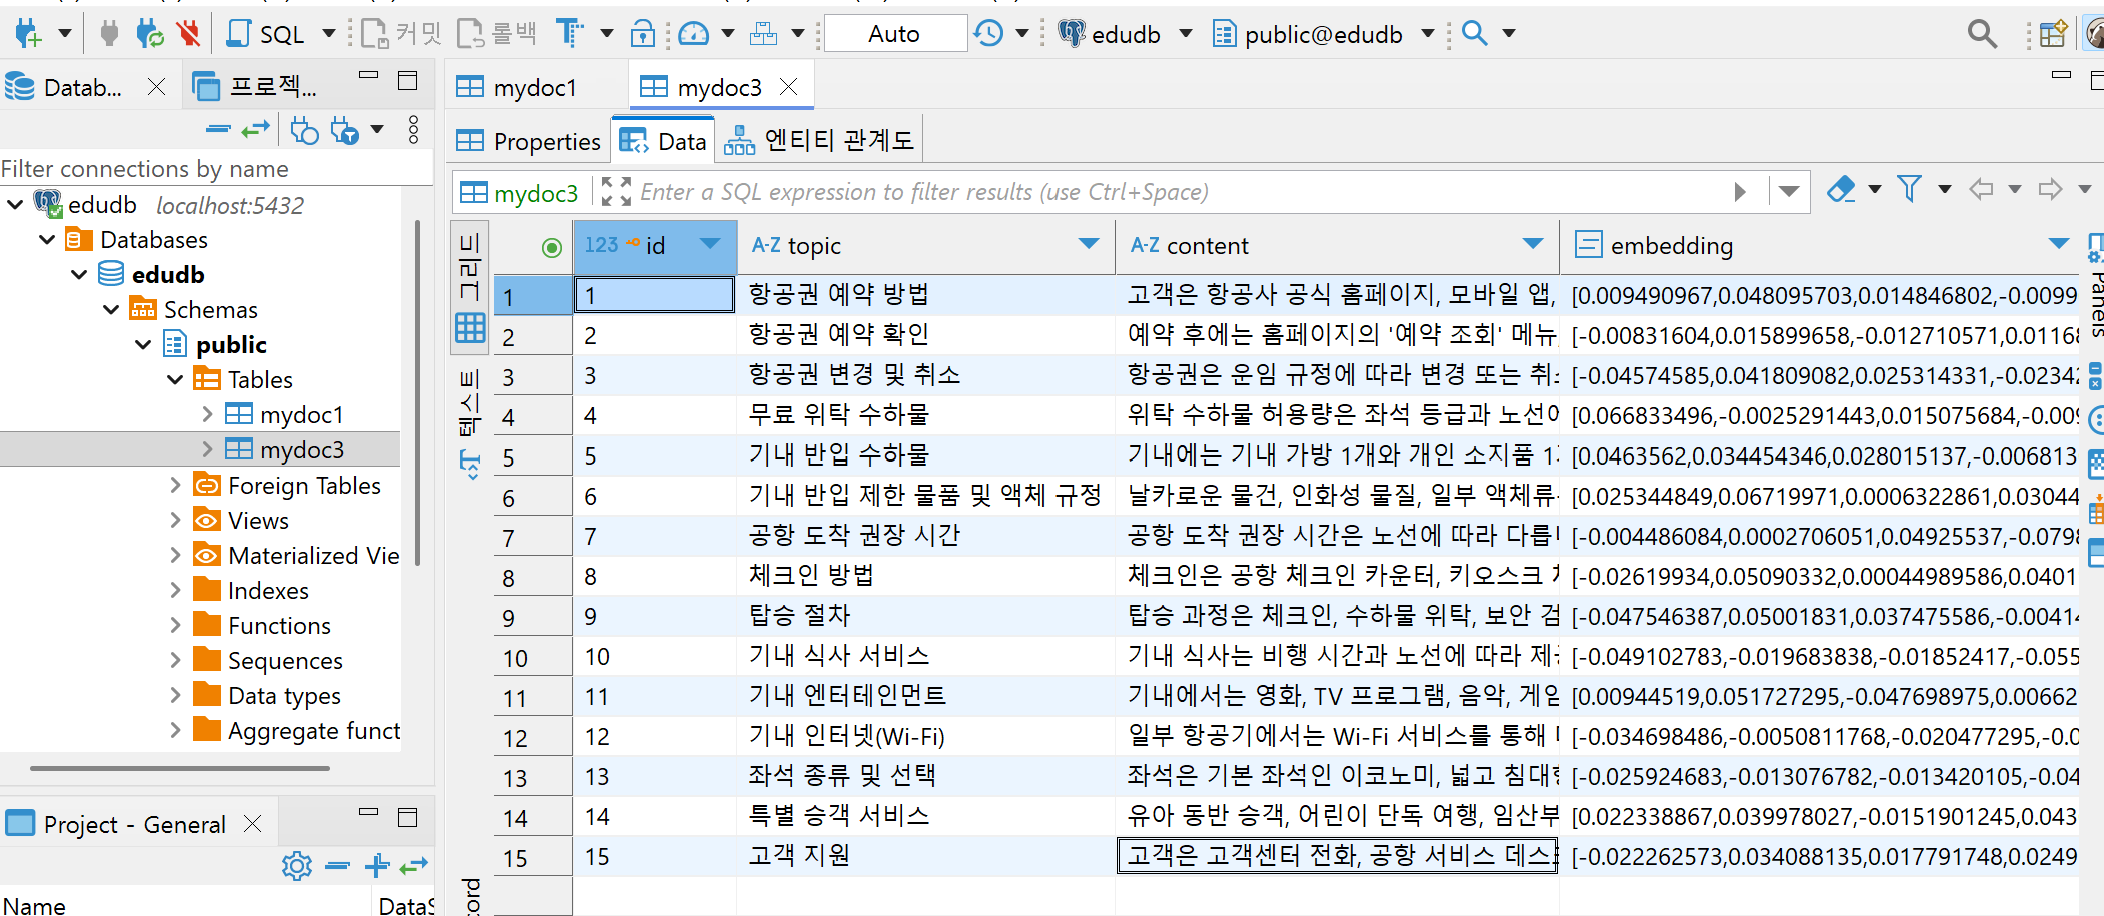

In [ ]:
question = "배가고프당... 음식을 빨리 먹을 수 있음 좋겠다"
results = search_knowledge_base(question, top_k=3)
 
print(f"\n'{question}'와 유사한 청크 {len(results)}개\n" + "-" * 40)
for i, r in enumerate(results, 1):
    print(f"{i}. [{r['topic']}]  (유사도 {r['similarity']})")
    print(f"   {r['content']}\n")

In [ ]:
%pip install pypdf

In [ ]:

import os
import psycopg
from openai import OpenAI
from pypdf import PdfReader

# 1. OpenAI 클라이언트 및 데이터베이스 설정
client = OpenAI()

DB_PARAMS = {
    "host": "localhost",
    "port": 5432,
    "user": "edu",
    "password": "1234",
    "dbname": "edudb"
}


# 2. OpenAI 임베딩 생성 (1536차원)
def get_embeddings(texts):
    response = client.embeddings.create(
        model="text-embedding-3-small",
        input=texts
    )
    return [
        item.embedding
        for item in sorted(response.data, key=lambda x: x.index)
    ]


# 3. PDF 로드 및 페이지 기반 청크 분할
def prepare_chunks_from_pdf(pdf_path, overlap_size=200):
    print(f"📖 PDF 파일 읽는 중: {pdf_path}")

    reader = PdfReader(pdf_path)

    chunks = []
    previous_context = ""

    for idx, page in enumerate(reader.pages):
        page_num = idx + 1
        raw_text = page.extract_text() or ""

        if not raw_text.strip():
            continue

        # 공백 및 줄바꿈 정리
        cleaned_text = " ".join(raw_text.split())

        # 이전 페이지의 마지막 200자 추가
        if previous_context:
            chunk_content = f"...{previous_context} {cleaned_text}"
        else:
            chunk_content = cleaned_text

        chunks.append({
            "page": page_num,
            "content": chunk_content
        })

        previous_context = cleaned_text[-overlap_size:]

    print(f"📝 총 {len(chunks)}개의 청크 생성 완료")
    return chunks


# 4. PDF 임베딩 및 pgvector 저장
def store_pdf_to_vector_db(pdf_path):

    # 1단계: PDF 청크 생성
    chunks = prepare_chunks_from_pdf(pdf_path)

    if not chunks:
        print("❌ PDF에서 텍스트를 추출하지 못했습니다.")
        return

    # 2단계: 임베딩 일괄 생성
    print("🧠 OpenAI 임베딩 생성 중...")

    vectors = get_embeddings([
        chunk["content"] for chunk in chunks
    ])

    # 3단계: 저장 데이터 준비
    data_to_insert = [
        (
            chunk["page"],
            chunk["content"],
            str(vector)
        )
        for chunk, vector in zip(chunks, vectors, strict=True)
    ]

    # 4단계: PostgreSQL 연결 및 데이터 저장
    print("🔌 PostgreSQL 연결 중...")

    with psycopg.connect(**DB_PARAMS) as conn:
        with conn.cursor() as cur:

            # pgvector 확장 및 테이블 생성
            cur.execute("CREATE EXTENSION IF NOT EXISTS vector;")
            cur.execute("DROP TABLE IF EXISTS mydoc4;")

            cur.execute("""
                CREATE TABLE mydoc4 (
                    id SERIAL PRIMARY KEY,
                    page INTEGER,
                    content TEXT,
                    embedding VECTOR(1536)
                );
            """)

            # psycopg3의 executemany() 사용
            print("💾 PostgreSQL에 벡터 데이터 저장 중...")

            cur.executemany(
                """
                INSERT INTO mydoc4 (page, content, embedding)
                VALUES (%s, %s, %s::vector)
                """,
                data_to_insert
            )

    print(f"🎉 총 {len(chunks)}개의 청크가 저장되었습니다!")


In [ ]:
PDF_FILE_PATH = "data/erp.pdf"
    
if os.path.exists(PDF_FILE_PATH):
    store_pdf_to_vector_db(PDF_FILE_PATH)
else:
    print(f"❌ {PDF_FILE_PATH} 파일이 존재하지 않습니다. 경로를 확인해 주세요.")

**📝 정리** — PDF(`data/erp.pdf`)를 페이지 단위로 자르고, 앞 페이지 끝 200자를 다음 청크 앞에 붙여(overlap) 문맥이 끊기지 않게 하는 코드다. 이 노트북에서는 위 검색 셀과 함께 실행하지 않아 결과가 없다. (PDF 파일은 다른 회사의 자료라 저장소에 넣지 않음)

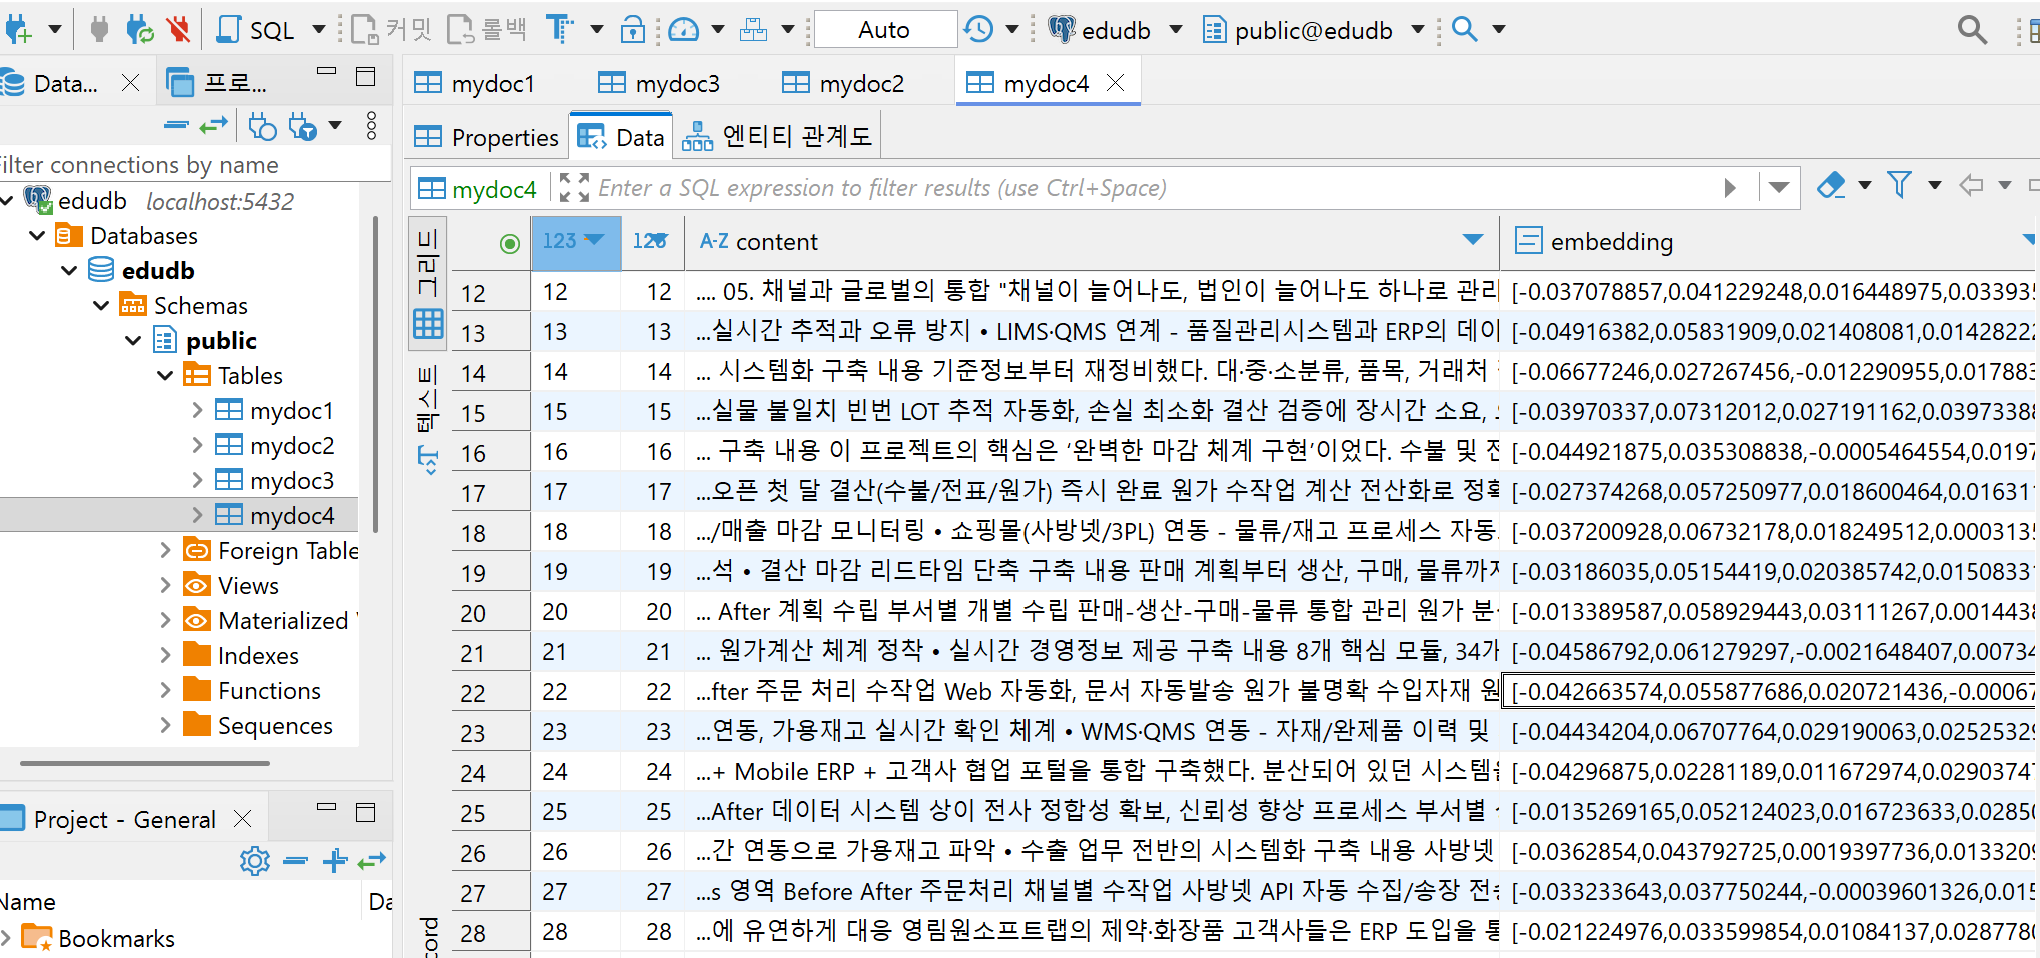

###  **벡터DB와 RAG** 기술에 대해 학습했습니다.

## 🔁 복습 질문

<details>
<summary>1. pgvector 테이블에서 임베딩 열의 타입은?</summary>

`vector(1536)` (임베딩 모델 차원과 같게).
</details>

<details>
<summary>2. 검색 결과를 프롬프트에 넣을 때 함께 넣으면 좋은 정보는?</summary>

문서 id·제목 같은 출처. 답변에 근거를 표시할 수 있다.
</details>
